# 2026-11-15-frozenseeded-fullgrid-p2p-trait-log

Spatial timeseries of logged trait prevalence for the 2026-11-15 frozen-seeded full-grid run with point-to-point immigrant exchange.
Adapted from `binder/wse-denovo-spatial2d-explicitsite-timeseries.ipynb` in mmore500/hypermutator-dynamics.

In [1]:
%load_ext watermark

In [2]:
import os

import downstream
import imageio
from IPython.display import display
import numpy as np
import polars as pl
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm

import pylib  # noqa: F401
from pylib.munge._addend_groups import addend_groups
from pylib.munge._union_upsample import union_upsample
from pylib.munge._squeeze import squeeze_int

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
%watermark -diwmuv -iv

Last updated: 2026-11-20T13:57:32.114809+00:00

Python implementation: CPython
Python version       : 3.10.12
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1070-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

pylib     : 0.0.0
downstream: 1.25.0
teeplot   : 1.4.2
numpy     : 2.1.2
imageio   : 2.37.0
polars    : 1.40.1
seaborn   : 0.13.2

Watermark: 2.4.3



In [4]:
teeplot_subdir = "2026-11-15-frozenseeded-fullgrid-p2p-trait-log"
teeplot_subdir

'2026-11-15-frozenseeded-fullgrid-p2p-trait-log'

## Prep Data

In [5]:
dfxs = pl.read_parquet("https://osf.io/jwuz7/download").with_row_index(
    "dstream_data_id",
)
display(dfxs.describe()), display(dfxs.head()), display(dfxs.tail());

statistic,dstream_data_id,tile,row,col,genomeFlavor,globalSeed,dispatchSlug,populationFlavor,memcpyMajor,nCol,nRow,nWav,nTrait,nCycle,nColSubgrid,nRowSubgrid,nonBlock,tilePopSize,tournSize,msec,tsc,replicate,_compconf_dummy,CEREBRASLIB_TRAITLOGGER_NUM_BITS,CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY,ASYNC_GA_P2P_SEND_PROBABILITY,CEREBRASLIB_TRAITLOGGER_DILATION,CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME,ASYNC_GA_FOSSIL_SAMPLING_MODE,ASYNC_GA_GENOME_FLAVOR,ASYNC_GA_POPULATION_FLAVOR,ASYNC_GA_POPSIZE,data_hex,dstream_algo,dstream_storage_bitoffset,dstream_storage_bitwidth,dstream_S,dstream_T_bitoffset,dstream_T_bitwidth,trait_value
str,f64,f64,f64,f64,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,str,str,str,str,f64,str,str,f64,f64,f64,f64,f64,f64
"""count""",883350.0,883350.0,883350.0,883350.0,"""883350""",883350.0,"""883350""","""883350""","""883350""",883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,883350.0,"""883350""",883350.0,883350.0,883350.0,883350.0,883350.0,"""883350""","""883350""","""883350""","""883350""",883350.0,"""883350""","""883350""",883350.0,883350.0,883350.0,883350.0,883350.0,883350.0
"""null_count""",0.0,0.0,0.0,0.0,"""0""",0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""",0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",441674.5,441674.5,584.5,377.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,0.0,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,null,null,0.0,1024.0,1024.0,1024.0,32.0,0.0
"""std""",255001.324482,255001.324482,337.749975,217.949659,null,0.0,null,null,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,null,null,null,null,0.0,null,null,0.0,0.0,0.0,0.0,0.0,0.0
"""min""",0.0,0.0,0.0,0.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,0.0,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,"""c3fbfbefffffffffffffffffffffff…",null,0.0,1024.0,1024.0,1024.0,32.0,0.0
"""25%""",220837.0,220837.0,292.0,188.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,null,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,null,null,0.0,1024.0,1024.0,1024.0,32.0,0.0
"""50%""",441675.0,441675.0,585.0,377.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,null,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,null,null,0.0,1024.0,1024.0,1024.0,32.0,0.0
"""75%""",662512.0,662512.0,877.0,566.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,null,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,null,null,0.0,1024.0,1024.0,1024.0,32.0,0.0
"""max""",883349.0,883349.0,1169.0,754.0,null,1115.0,null,null,null,755.0,1170.0,1.0,2.0,50000.0,0.0,0.0,0.0,1133.0,2.0,0.0,0.0,null,42.0,1024.0,0.0,0.0005,8.0,null,null,null,null,1133.0,"""ffffffffffffffffffffffffffffff…",null,0.0,1024.0,1024.0,1024.0,32.0,0.0


dstream_data_id,tile,row,col,genomeFlavor,globalSeed,dispatchSlug,populationFlavor,memcpyMajor,nCol,nRow,nWav,nTrait,nCycle,nColSubgrid,nRowSubgrid,nonBlock,tilePopSize,tournSize,msec,tsc,replicate,_compconf_dummy,CEREBRASLIB_TRAITLOGGER_NUM_BITS,CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY,ASYNC_GA_P2P_SEND_PROBABILITY,CEREBRASLIB_TRAITLOGGER_DILATION,CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME,ASYNC_GA_FOSSIL_SAMPLING_MODE,ASYNC_GA_GENOME_FLAVOR,ASYNC_GA_POPULATION_FLAVOR,ASYNC_GA_POPSIZE,data_hex,dstream_algo,dstream_storage_bitoffset,dstream_storage_bitwidth,dstream_S,dstream_T_bitoffset,dstream_T_bitwidth,trait_value
u64,u32,u16,u16,cat,u32,cat,cat,cat,u16,u16,u8,u8,u32,u16,u16,bool,u16,f32,f32,u64,cat,u32,u32,f32,f32,u32,cat,cat,cat,cat,u32,str,cat,u16,u16,u16,u16,u16,u16
0,0,0,0,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""ffffffffffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
1,1,0,1,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""ffffffffffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
2,2,0,2,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""ffffffffffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
3,3,0,3,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""ffffffffffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
4,4,0,4,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""ffffffffffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0


dstream_data_id,tile,row,col,genomeFlavor,globalSeed,dispatchSlug,populationFlavor,memcpyMajor,nCol,nRow,nWav,nTrait,nCycle,nColSubgrid,nRowSubgrid,nonBlock,tilePopSize,tournSize,msec,tsc,replicate,_compconf_dummy,CEREBRASLIB_TRAITLOGGER_NUM_BITS,CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY,ASYNC_GA_P2P_SEND_PROBABILITY,CEREBRASLIB_TRAITLOGGER_DILATION,CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME,ASYNC_GA_FOSSIL_SAMPLING_MODE,ASYNC_GA_GENOME_FLAVOR,ASYNC_GA_POPULATION_FLAVOR,ASYNC_GA_POPSIZE,data_hex,dstream_algo,dstream_storage_bitoffset,dstream_storage_bitwidth,dstream_S,dstream_T_bitoffset,dstream_T_bitwidth,trait_value
u64,u32,u16,u16,cat,u32,cat,cat,cat,u16,u16,u8,u8,u32,u16,u16,bool,u16,f32,f32,u64,cat,u32,u32,f32,f32,u32,cat,cat,cat,cat,u32,str,cat,u16,u16,u16,u16,u16,u16
883345,883345,1169,750,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""c3fbfbefffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
883346,883346,1169,751,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""c3fbfbefffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
883347,883347,1169,752,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""c3fbfbefffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
883348,883348,1169,753,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""c3fbfbefffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0
883349,883349,1169,754,"""genome_frozenseeded_2026_11_15""",1115,"""p2p-pairs""","""population_tournamentsteadysta…","""ROW_MAJOR""",755,1170,1,2,50000,0,0,false,1133,2.0,0.0,0,"""fb669295-10be-4423-b7d7-c3d5d6…",42,1024,0.0,0.0005,8,"""hybrid_0_steady_1_stretched_2_…","""snapshot""","""genome_frozenseeded_2026_11_15""","""population_tournamentsteadysta…",1133,"""c3fbfbefffffffffffffffffffffff…","""dstream.hybrid_0_steady_1_stre…",0,1024,1024,1024,32,0


In [6]:
def unpack_logger_timeseries_data(df: pl.DataFrame) -> pl.DataFrame:

    # sample every 64th tile
    df = df.filter((pl.col("col") % 8 == 0) & (pl.col("row") % 8 == 0))

    # unpack dstream data items from logger hex strings
    dfu = downstream.dataframe.unpack_data_packed(df)
    df = downstream.dataframe.explode_lookup_unpacked(
        dfu.with_columns(
            # fast forward loggers to at least dstream_S entries
            # (i.e., buffer filled)
            # these will be semantically-correct zero values
            dstream_T=pl.max_horizontal(
                pl.col("dstream_T"), pl.col("dstream_S")
            ),
        ),
        value_type="uint8",
    )

    # join metadata onto unpacked data
    df = df.join(
        dfu.select(
            "dstream_data_id",
            "CEREBRASLIB_TRAITLOGGER_DILATION",
            "col",
            "replicate",
            "row",
            "tile",
        ),
        on="dstream_data_id",
    )

    # apply dilation to dstream_T and dstream_Tbar
    df = df.with_columns(
        dstream_T=pl.col("dstream_T")
        * pl.col("CEREBRASLIB_TRAITLOGGER_DILATION"),
        dstream_Tbar=pl.col("dstream_Tbar")
        * pl.col("CEREBRASLIB_TRAITLOGGER_DILATION"),
    )

    # addend time time series groups with final zero value entry
    df = addend_groups(
        df,
        group_by=["replicate", "tile"],
        aggs=(
            pl.col("col").unique().pipe(squeeze_int),
            (pl.col("dstream_Tbar") + 1).max().alias("dstream_Tbar"),
            pl.lit(0).alias("dstream_value"),
            pl.col("row").unique().pipe(squeeze_int),
        ),
        inner_only=True,
    )

    # upsample to fill in dstream_Tbar dropped by some loggers
    # prevents ampling biases from longer-running vs shorter-running loggers
    df = union_upsample(
        df,
        upsample="dstream_Tbar",
        group_by="tile",
        fill_null_ops=[
            (pl.all(), {"strategy": "forward"}),
            (pl.col("dstream_Tbar", "dstream_value"), {"strategy": "zero"}),
            (pl.all(), {"strategy": "backward"}),
        ],
    )
    assert len(df["dstream_Tbar"].value_counts()["count"].unique()) == 1

    return df

In [7]:
res = []
for _, df in tqdm(dfxs.group_by("replicate")):
    df = unpack_logger_timeseries_data(df)
    res.append(df)

df = pl.concat(res)

0it [00:00, ?it/s]/usr/local/lib/python3.10/dist-packages/downstream/dataframe/_impl/_check_downstream_version.py:34: UserWarning: Dataframe downstream_version column not provided
  warnings.warn(
1it [00:30, 30.19s/it]


## Plot Data

In [8]:
# take the mean of dstream_value at each dstream_Tbar across tiles
df_mean = df.group_by("replicate", "dstream_Tbar").agg(
    pl.col("dstream_value").mean(),
)

teeplots/2026-11-15-frozenseeded-fullgrid-p2p-trait-log/hue=replicate+kind=line+viz=relplot+x=dstream-tbar+y=dstream-value+ext=.pdf
teeplots/2026-11-15-frozenseeded-fullgrid-p2p-trait-log/hue=replicate+kind=line+viz=relplot+x=dstream-tbar+y=dstream-value+ext=.png


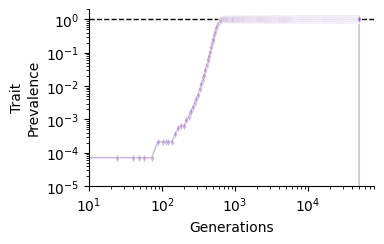

In [9]:
with tp.teed(
    sns.relplot,
    data=df_mean.sort("dstream_Tbar"),
    x="dstream_Tbar",
    y="dstream_value",
    hue="replicate",
    alpha=0.5,
    aspect=1.5,
    errorbar=None,
    height=2.5,
    linewidth=1,
    legend=False,
    kind="line",
    marker="d",
    markersize=4,
    teeplot_subdir=teeplot_subdir,
    teeplot_outexclude=["marker"],
) as g:
    g.set(xlim=(10, 80000))
    g.set(ylim=(0.00001, 2))
    g.set_axis_labels(x_var="Generations", y_var="Trait\nPrevalence")
    for ax in g.axes.flat:
        ax.axhline(1, ls="--", color="black", linewidth=1, zorder=-10)
        ax.set_yscale("log")
        ax.set_xscale("log")

## Animate Data

In [10]:
os.makedirs(teeplot_subdir, exist_ok=True)

for (replicate,), dfr in tqdm(df.group_by("replicate")):
    frames = []
    for (dstream_Tbar,), dff in dfr.sort("dstream_Tbar").group_by(
        "dstream_Tbar", maintain_order=True
    ):

        dff = dff.with_columns(
            col_rank=pl.col("col").rank(method="dense").cast(pl.Int32) - 1,
            row_rank=pl.col("row").rank(method="dense").cast(pl.Int32) - 1,
        )

        num_rows = dff["row_rank"].max() + 1
        num_cols = dff["col_rank"].max() + 1

        frame = np.empty((num_rows, num_cols), dtype=np.uint8)
        frame[dff["row_rank"], dff["col_rank"]] = dff["dstream_value"] * 255
        frame = np.kron(frame, np.ones((4, 4), dtype=frame.dtype))
        frames.append((dstream_Tbar, frame))

        outdir = f"{teeplot_subdir}/a=traitframes+rep={replicate}"
        os.makedirs(outdir, exist_ok=True)
        outpath = f"{outdir}/dstream_Tbar={dstream_Tbar:06}+ext=.png"
        imageio.imwrite(outpath, frame.T)

    print(len(frames))
    outpath = f"{teeplot_subdir}/a=traits+rep={replicate}+ext=.gif"
    imageio.mimsave(outpath, [f for _, f in frames], duration=0.2)

    # sweep completes within first ~1000 generations; animate that window
    sweep = [f.T for t, f in frames if t <= 1000]
    print(len(sweep))
    outpath = f"{teeplot_subdir}/a=traits-sweep+rep={replicate}+tbar_max=1000+ext=.gif"
    imageio.mimsave(outpath, sweep, duration=0.1, loop=0)

0it [00:00, ?it/s]

1025
74


1it [00:08,  8.27s/it]
